In [1]:
!nvidia-smi

Sun Oct 11 20:54:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

CUDA Available: True
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [3]:
!python -c "import socket; print(socket.gethostbyname('github.com'))"

140.82.114.3


In [4]:
!git clone https://github.com/Usman-LUMS/small-model-alignment-starter.git /kaggle/working/small-model-alignment-starter

Cloning into '/kaggle/working/small-model-alignment-starter'...
remote: Enumerating objects: 332, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 332 (delta 11), reused 11 (delta 9), pack-reused 314 (from 1)
Receiving objects: 100% (332/332), 1.07 MiB | 32.10 MiB/s, done.
Resolving deltas: 100% (186/186), done.


In [5]:
%cd /kaggle/working/small-model-alignment-starter

!pip uninstall -y -q torchao
!pip install -q -r requirements.txt
!pip install -q -e . --no-deps

/kaggle/working/small-model-alignment-starter
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 82.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 87.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Pr

In [6]:
!python -m pytest -q tests/test_public_adapter_smoke.py
!git log -1 --oneline

.......                                                                  [100%]
7 passed in 2.15s
1e04760 (HEAD -> main, origin/main, origin/HEAD) Implement SFT and DPO core functions


In [7]:
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_NAME = "Qwen/Qwen2.5-0.5B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
).to("cuda:0")

model.eval()

print("Model loaded:", MODEL_NAME)
print("Parameters:", sum(p.numel() for p in model.parameters()))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Model loaded: Qwen/Qwen2.5-0.5B
Parameters: 494032768


In [8]:
from datasets import load_dataset

SEED = 42
NUM_PROMPTS = 300

DATA_URL = (
    "https://huggingface.co/datasets/tatsu-lab/alpaca_eval/"
    "resolve/main/alpaca_eval.json"
)

dataset = load_dataset(
    "json",
    data_files=DATA_URL,
    split="train"
)

print("Total examples:", len(dataset))
print("Columns:", dataset.column_names)
print("Example:", dataset[0])

alpaca_eval.json: 0.00B [00:00, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Total examples: 805
Columns: ['dataset', 'instruction', 'output', 'generator']
Example: {'dataset': 'helpful_base', 'instruction': 'What are the names of some famous actors that started their careers on Broadway?', 'output': 'Some famous actors that started their careers on Broadway include: \n1. Hugh Jackman \n2. Meryl Streep \n3. Denzel Washington \n4. Julia Roberts \n5. Christopher Walken \n6. Anthony Rapp \n7. Audra McDonald \n8. Nathan Lane \n9. Sarah Jessica Parker \n10. Lin-Manuel Miranda', 'generator': 'text_davinci_003'}


In [9]:
import json
import random
from pathlib import Path

random.seed(SEED)

indices = random.sample(range(len(dataset)), NUM_PROMPTS)

eval_data = []

for idx in indices:
    example = dataset[idx]

    eval_data.append({
        "id": str(idx),
        "instruction": example["instruction"]
    })

output_dir = Path("outputs/baseline")
output_dir.mkdir(parents=True, exist_ok=True)

eval_path = output_dir / "alpaca_eval_300_seed42.json"

with open(eval_path, "w", encoding="utf-8") as f:
    json.dump(eval_data, f, indent=2, ensure_ascii=False)

print("Evaluation prompts:", len(eval_data))
print("Saved:", eval_path)

Evaluation prompts: 300
Saved: outputs/baseline/alpaca_eval_300_seed42.json


In [10]:
def generate_response(instruction, max_new_tokens=128):
    prompt = f"### Instruction:\n{instruction}\n\n### Response:\n"

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to("cuda:0")

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()


for example in eval_data[:3]:
    response = generate_response(example["instruction"])

    print("\nINSTRUCTION:", example["instruction"])
    print("RESPONSE:", response)
    print("-" * 70)


INSTRUCTION: Create a short, concise summary of the paper based on its abstract.

Few-shot learning (FSL) is one of the key future steps in machine learning and raises a lot of attention. In this paper, we focus on the FSL problem of dialogue understanding, which contains two closely related tasks: intent detection and slot filling. Dialogue understanding has been proven to benefit a lot from jointly learning the two sub-tasks. However, such joint learning becomes challenging in the few-shot scenarios: on the one hand, the sparsity of samples greatly magnifies the difficulty of modeling the connection between the two tasks; on the other hand, how to jointly learn multiple tasks in the few-shot setting is still less investigated. In response to this, we introduce FewJoint, the first FSL benchmark for joint dialogue understanding. FewJoint provides a new corpus with 59 different dialogue domains from real industrial API and a code platform to ease FSL experiment set-up, which are expect

In [11]:
from tqdm.auto import tqdm

baseline_results = []

for example in tqdm(eval_data, desc="Baseline generation"):
    response = generate_response(
        example["instruction"],
        max_new_tokens=128
    )

    baseline_results.append({
        "id": example["id"],
        "instruction": example["instruction"],
        "output": response,
        "generator": "qwen2.5-0.5b-base",
        "dataset": "alpaca_eval"
    })

    # Save progress every 25 examples
    if len(baseline_results) % 25 == 0:
        with open(
            output_dir / "baseline_progress.json",
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                baseline_results,
                f,
                indent=2,
                ensure_ascii=False
            )

print("Generated:", len(baseline_results))

Baseline generation:   0%|          | 0/300 [00:00<?, ?it/s]

Generated: 300


In [12]:
final_path = output_dir / "qwen_base_alpaca_eval_300.json"

with open(final_path, "w", encoding="utf-8") as f:
    json.dump(
        baseline_results,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Saved:", final_path)
print("Total responses:", len(baseline_results))

assert len(baseline_results) == 300
assert all("output" in item for item in baseline_results)

Saved: outputs/baseline/qwen_base_alpaca_eval_300.json
Total responses: 300


In [13]:
for example in baseline_results[:5]:
    print("=" * 80)
    print("Instruction:", example["instruction"])
    print("\nGenerated response:")
    print(example["output"])

Instruction: Create a short, concise summary of the paper based on its abstract.

Few-shot learning (FSL) is one of the key future steps in machine learning and raises a lot of attention. In this paper, we focus on the FSL problem of dialogue understanding, which contains two closely related tasks: intent detection and slot filling. Dialogue understanding has been proven to benefit a lot from jointly learning the two sub-tasks. However, such joint learning becomes challenging in the few-shot scenarios: on the one hand, the sparsity of samples greatly magnifies the difficulty of modeling the connection between the two tasks; on the other hand, how to jointly learn multiple tasks in the few-shot setting is still less investigated. In response to this, we introduce FewJoint, the first FSL benchmark for joint dialogue understanding. FewJoint provides a new corpus with 59 different dialogue domains from real industrial API and a code platform to ease FSL experiment set-up, which are expecte

In [14]:
import shutil

archive_path = shutil.make_archive(
    "/kaggle/working/pa2_baseline_outputs",
    "zip",
    root_dir=str(output_dir)
)

print("Archive created:", archive_path)

Archive created: /kaggle/working/pa2_baseline_outputs.zip


In [15]:
import os
import json
import random
import numpy as np
import torch

from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/small-model-alignment-starter")
os.chdir(PROJECT_DIR)

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B"

# First run a small training smoke test.
# Change to "full" after the smoke test succeeds.
RUN_MODE = "smoke"

TRAIN_SIZE = 64 if RUN_MODE == "smoke" else 30000
VAL_SIZE = 32 if RUN_MODE == "smoke" else 1000

MAX_LENGTH = 512
MAX_PROMPT_LENGTH = 256

BATCH_SIZE = 2
GRAD_ACCUM = 16
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.1
EPOCHS = 1

OUTPUT_DIR = PROJECT_DIR / "outputs" / f"sft_{RUN_MODE}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Mode:", RUN_MODE)
print("Training examples:", TRAIN_SIZE)
print("Validation examples:", VAL_SIZE)
print("Output:", OUTPUT_DIR)

Mode: smoke
Training examples: 64
Validation examples: 32
Output: /kaggle/working/small-model-alignment-starter/outputs/sft_smoke


In [16]:
from datasets import load_dataset

raw_train = load_dataset(
    "HuggingFaceH4/ultrachat_200k",
    split="train_sft[:50000]"
)

raw_val = load_dataset(
    "HuggingFaceH4/ultrachat_200k",
    split="test_sft[:3000]"
)

def extract_pairs(dataset, limit, seed):
    examples = []

    shuffled = dataset.shuffle(seed=seed)

    for row in shuffled:
        messages = row["messages"]

        if len(messages) < 2:
            continue

        if messages[0]["role"] != "user":
            continue

        if messages[1]["role"] != "assistant":
            continue

        prompt = messages[0]["content"].strip()
        response = messages[1]["content"].strip()

        if prompt and response:
            examples.append({
                "prompt": prompt,
                "response": response
            })

        if len(examples) == limit:
            break

    if len(examples) != limit:
        raise ValueError(
            f"Expected {limit} examples, got {len(examples)}"
        )

    return examples


train_examples = extract_pairs(raw_train, TRAIN_SIZE, SEED)
val_examples = extract_pairs(raw_val, VAL_SIZE, SEED)

print("Train:", len(train_examples))
print("Validation:", len(val_examples))
print("Example instruction:", train_examples[0]["prompt"][:200])
print("Example response:", train_examples[0]["response"][:200])

with open(OUTPUT_DIR / "data_manifest.json", "w") as f:
    json.dump({
        "source": "HuggingFaceH4/ultrachat_200k",
        "train_split": "train_sft",
        "validation_split": "test_sft",
        "seed": SEED,
        "train_examples": len(train_examples),
        "validation_examples": len(val_examples),
        "selection": "first user/assistant pair after seeded shuffle"
    }, f, indent=2)

README.md: 0.00B [00:00, ?B/s]

data/train_sft-00000-of-00003-a3ecf92756(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/train_sft-00001-of-00003-0a1804bcb6(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/train_sft-00002-of-00003-ee46ed25cf(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/test_sft-00000-of-00001-f7dfac4afe5(…):   0%|          | 0.00/81.2M [00:00<?, ?B/s]

...

Generating train_sft split:   0%|          | 0/207865 [00:00<?, ? examples/s]

Generating test_sft split:   0%|          | 0/23110 [00:00<?, ? examples/s]

Generating train_gen split:   0%|          | 0/256032 [00:00<?, ? examples/s]

Generating test_gen split:   0%|          | 0/28304 [00:00<?, ? examples/s]

Train: 64
Validation: 32
Example instruction: Which museums in Bangkok have the most interactive exhibits or unique displays?
Example response: 1. Museum Siam - Known for its interactive exhibits that offer a unique look into Thai history and culture.

2. The National Museum Bangkok - Offers a vast collection of artifacts from Thailand's rich


In [17]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token


def tokenize_example(example):
    prompt = (
        "### Instruction:\n"
        + example["prompt"]
        + "\n\n### Response:\n"
    )

    prompt_ids = tokenizer.encode(
        prompt,
        add_special_tokens=False
    )[:MAX_PROMPT_LENGTH]

    response_ids = tokenizer.encode(
        example["response"],
        add_special_tokens=False
    )

    if tokenizer.eos_token_id is not None:
        response_ids.append(tokenizer.eos_token_id)

    available = MAX_LENGTH - len(prompt_ids)
    response_ids = response_ids[:available]

    input_ids = prompt_ids + response_ids

    labels = (
        [-100] * len(prompt_ids)
        + response_ids
    )

    return {
        "input_ids": input_ids,
        "labels": labels
    }


class SFTDataset(Dataset):
    def __init__(self, examples):
        self.data = [
            tokenize_example(x)
            for x in examples
        ]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


def collate_fn(batch):
    width = max(len(x["input_ids"]) for x in batch)

    input_ids = []
    labels = []
    attention_masks = []

    for example in batch:
        length = len(example["input_ids"])
        pad = width - length

        input_ids.append(
            example["input_ids"]
            + [tokenizer.pad_token_id] * pad
        )

        labels.append(
            example["labels"] + [-100] * pad
        )

        attention_masks.append(
            [1] * length + [0] * pad
        )

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_masks, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long)
    }


train_dataset = SFTDataset(train_examples)
val_dataset = SFTDataset(val_examples)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

sample = next(iter(train_loader))

print("Input shape:", sample["input_ids"].shape)
print("Labels shape:", sample["labels"].shape)
print("Response tokens:", (sample["labels"] != -100).sum().item())

assert (sample["labels"] != -100).sum().item() > 0
assert sample["input_ids"].shape == sample["labels"].shape

Input shape: torch.Size([2, 512])
Labels shape: torch.Size([2, 512])
Response tokens: 703


In [18]:
from transformers import AutoModelForCausalLM

device = torch.device("cuda:0")

# Release previous inference model to save GPU memory.
if "model" in globals():
    del model
    import gc
    gc.collect()
    torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32
)

model.to(device)
model.train()

model.config.use_cache = False
model.gradient_checkpointing_enable()

print("Model:", MODEL_NAME)
print("Device:", next(model.parameters()).device)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Model dtype:", next(model.parameters()).dtype)

Model: Qwen/Qwen2.5-0.5B
Device: cuda:0
Trainable parameters: 494032768
Model dtype: torch.float32


In [19]:
import math
from transformers import get_cosine_schedule_with_warmup

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

steps_per_epoch = math.ceil(
    len(train_loader) / GRAD_ACCUM
)

TOTAL_STEPS = steps_per_epoch * EPOCHS
WARMUP_STEPS = max(1, int(TOTAL_STEPS * 0.03))

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=WARMUP_STEPS,
    num_training_steps=TOTAL_STEPS
)

scaler = torch.amp.GradScaler("cuda")

print("Optimizer: AdamW")
print("Total optimizer steps:", TOTAL_STEPS)
print("Warmup steps:", WARMUP_STEPS)
print("Gradient accumulation:", GRAD_ACCUM)

Optimizer: AdamW
Total optimizer steps: 2
Warmup steps: 1
Gradient accumulation: 16


In [20]:
from tqdm.auto import tqdm
import torch.nn.functional as F

training_history = []
best_val_loss = float("inf")


def compute_batch_loss(batch):
    inputs = {
        key: value.to(device)
        for key, value in batch.items()
    }

    with torch.autocast("cuda", dtype=torch.float16):
        outputs = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

    # Shift for causal language modeling.
    logits = outputs.logits[:, :-1, :].float()
    labels = inputs["labels"][:, 1:]

    # Only response tokens contribute to loss.
    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        labels.reshape(-1),
        ignore_index=-100
    )

    return loss


@torch.no_grad()
def evaluate_sft():
    model.eval()
    losses = []

    for batch in val_loader:
        loss = compute_batch_loss(batch)
        losses.append(loss.item())

    model.train()

    return sum(losses) / len(losses)


def save_checkpoint(name):
    path = OUTPUT_DIR / name
    path.mkdir(parents=True, exist_ok=True)

    model.save_pretrained(
        path,
        safe_serialization=True
    )
    tokenizer.save_pretrained(path)

    print("Checkpoint saved:", path)


def save_metrics(record):
    with open(
        OUTPUT_DIR / "metrics.jsonl",
        "a",
        encoding="utf-8"
    ) as f:
        f.write(json.dumps(record) + "\n")


print("Training functions initialized.")

Training functions initialized.


In [21]:
import time

start_time = time.time()
global_step = 0
optimizer.zero_grad(set_to_none=True)

for epoch in range(EPOCHS):

    model.train()
    epoch_losses = []

    progress = tqdm(
        train_loader,
        desc=f"SFT Epoch {epoch + 1}/{EPOCHS}"
    )

    accumulated = 0

    for batch_idx, batch in enumerate(progress):

        loss = compute_batch_loss(batch)
        epoch_losses.append(loss.item())

        scaled_loss = loss / GRAD_ACCUM

        scaler.scale(scaled_loss).backward()
        accumulated += 1

        is_last_batch = batch_idx == len(train_loader) - 1

        if accumulated == GRAD_ACCUM or is_last_batch:

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            optimizer.zero_grad(set_to_none=True)
            accumulated = 0

            global_step += 1

            progress.set_postfix(
                loss=f"{loss.item():.4f}",
                step=global_step
            )

            eval_interval = (
                1 if RUN_MODE == "smoke" else 100
            )

            if global_step % eval_interval == 0 or global_step == TOTAL_STEPS:

                val_loss = evaluate_sft()

                record = {
                    "step": global_step,
                    "epoch": epoch + 1,
                    "train_loss": sum(epoch_losses) / len(epoch_losses),
                    "val_loss": val_loss,
                    "lr": scheduler.get_last_lr()[0]
                }

                training_history.append(record)
                save_metrics(record)

                print(
                    f"Step {global_step} | "
                    f"Train: {record['train_loss']:.4f} | "
                    f"Validation: {val_loss:.4f}"
                )

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    save_checkpoint("best")

save_checkpoint("final")

elapsed = (time.time() - start_time) / 60

print("Training complete!")
print("Minutes:", round(elapsed, 2))
print("Best validation loss:", best_val_loss)

SFT Epoch 1/1:   0%|          | 0/32 [00:00<?, ?it/s]

Step 1 | Train: 1.4511 | Validation: 1.4716
Checkpoint saved: /kaggle/working/small-model-alignment-starter/outputs/sft_smoke/best
Step 2 | Train: 1.4649 | Validation: 1.4684
Checkpoint saved: /kaggle/working/small-model-alignment-starter/outputs/sft_smoke/best
Checkpoint saved: /kaggle/working/small-model-alignment-starter/outputs/sft_smoke/final
Training complete!
Minutes: 0.39
Best validation loss: 1.4683938547968864


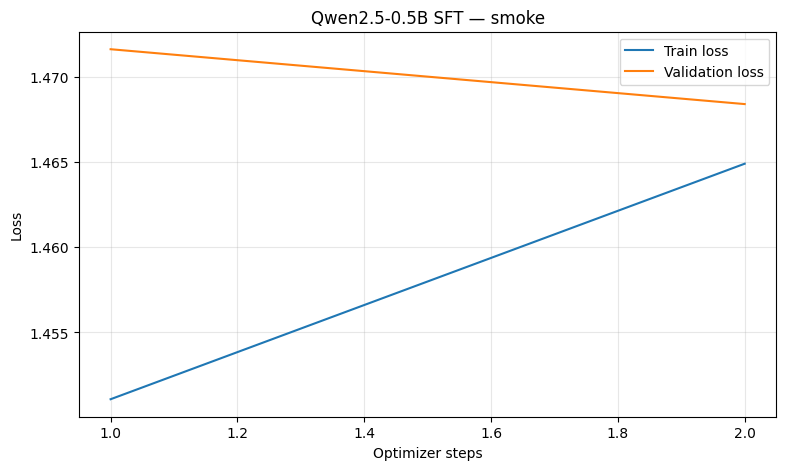

In [22]:
import matplotlib.pyplot as plt

steps = [x["step"] for x in training_history]
train_losses = [x["train_loss"] for x in training_history]
val_losses = [x["val_loss"] for x in training_history]

plt.figure(figsize=(9, 5))
plt.plot(steps, train_losses, label="Train loss")
plt.plot(steps, val_losses, label="Validation loss")

plt.xlabel("Optimizer steps")
plt.ylabel("Loss")
plt.title(f"Qwen2.5-0.5B SFT — {RUN_MODE}")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    OUTPUT_DIR / "sft_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [23]:
from pathlib import Path

best_path = OUTPUT_DIR / "best"
final_path = OUTPUT_DIR / "final"

print("Best checkpoint exists:", best_path.exists())
print("Final checkpoint exists:", final_path.exists())

assert (best_path / "config.json").exists()
assert (final_path / "config.json").exists()

print("SFT checkpoints verified.")

Best checkpoint exists: True
Final checkpoint exists: True
SFT checkpoints verified.


In [24]:
import shutil

archive = shutil.make_archive(
    f"/kaggle/working/pa2_sft_{RUN_MODE}",
    "zip",
    root_dir=str(OUTPUT_DIR)
)

print("Archive created:", archive)

Archive created: /kaggle/working/pa2_sft_smoke.zip
